<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/advanced_cnn_models/10_HRNetV2_HRNet_W48.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for HRNetV2_HRNet-W48  on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
# Install dependencies
!pip install -q webdataset albumentations timm

# Imports
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import random
import warnings
warnings.filterwarnings("ignore")

print("✅ HRNet-W48 Environment Ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 1.7 MB/s eta 0:00:00
Mounted at /content/drive
✅ HRNet-W48 Environment Ready!


In [ ]:
drive_dataset_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/WebDataset/snow_patches_5000_random.tar"
colab_dataset_path = "/tmp/snow_patches_5000_random.tar"

os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
print("📥 Copying dataset...")
shutil.copy(drive_dataset_path, colab_dataset_path)
print(f"✅ Dataset: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Device: {device}")
wds_path = colab_dataset_path

📥 Copying dataset...
✅ Dataset: 0.41 GB
🚀 Device: cuda


In [ ]:
MODEL_NAME = "HRNetV2_W48"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results Path: {model_results_path}")

📁 Results Path: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/HRNetV2_W48


In [ ]:
CONFIG = {
    "model_name": MODEL_NAME,
    "encoder_name": "hrnet_w48",
    "num_epochs": 50,
    "batch_size": 16,
    "learning_rate": 1e-4,
    "num_workers": 0,
    "total_patches": 5000
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

print(f"📊 Train/Val/Test Split: {CONFIG['train_size']}/{CONFIG['val_size']}/{CONFIG['test_size']}")

📊 Train/Val/Test Split: 3500/1000/500


In [ ]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk = np.array(sample["mask.png"].convert("L")) / 255.0
    t = transform(image=img, mask=msk)
    return t["image"], t["mask"].unsqueeze(0)

In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(val_batches)

print("✅ Data loaders ready!")

✅ Data loaders ready!


In [ ]:
class HRNetSegmentation(nn.Module):
    def __init__(self, model_name='hrnet_w48', out_channels=1):
        super(HRNetSegmentation, self).__init__()
        # Load HRNet-W48 with ImageNet weights
        self.backbone = timm.create_model(model_name, pretrained=True, features_only=True)

        # Get the actual number of channels from the backbone's first feature map
        # This fixes the "expected 48 but got 64" error dynamically
        encoder_channels = self.backbone.feature_info.channels()
        first_feature_channels = encoder_channels[0]
        print(f"DEBUG: Detected backbone output channels: {encoder_channels}")
        print(f"✅ Using {first_feature_channels} channels for segmentation head.")

        self.seg_head = nn.Sequential(
            nn.Conv2d(first_feature_channels, first_feature_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(first_feature_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(first_feature_channels, out_channels, kernel_size=1)
        )

    def forward(self, x):
        input_size = x.shape[2:]
        features = self.backbone(x)

        # Use features[0] which is the high-resolution stream
        x = self.seg_head(features[0])

        # Upsample back to 256x256
        x = F.interpolate(x, size=input_size, mode='bilinear', align_corners=True)
        return x

model = HRNetSegmentation().to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"✅ HRNet V2 Built! Parameters: {total_params:,}")

DEBUG: Detected backbone output channels: [64, 128, 256, 512, 1024]
✅ Using 64 channels for segmentation head.
✅ HRNet V2 Built! Parameters: 67,156,161


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self): super().__init__(); self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred, target):
        bce = self.bce(pred, target)
        p = torch.sigmoid(pred)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + 1e-6) / (p.sum() + target.sum() + 1e-6)
        return 0.5 * bce + 0.5 * dice

def calc_iou(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + 1e-6) / (union + 1e-6)

def calc_dice(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    return (2 * inter + 1e-6) / (pred.sum() + target.sum() + 1e-6)

def calc_precision(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (pred.sum() + 1e-6)

def calc_recall(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (target.sum() + 1e-6)

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=5, factor=0.5)

history = {"train_loss":[], "val_loss":[], "train_iou":[], "val_iou":[],
           "train_dice":[], "val_dice":[], "train_precision":[], "val_precision":[],
           "train_recall":[], "val_recall":[], "learning_rate":[]}

best_dice = 0.0

In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    metrics = {k: [] for k in ["loss", "iou", "dice", "precision", "recall"]}
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        metrics["loss"].append(loss.item())
        metrics["iou"].append(calc_iou(preds, msks).item())
        metrics["dice"].append(calc_dice(preds, msks).item())
        metrics["precision"].append(calc_precision(preds, msks).item())
        metrics["recall"].append(calc_recall(preds, msks).item())
        pbar.set_postfix(loss=f"{np.mean(metrics['loss']):.4f}", dice=f"{np.mean(metrics['dice']):.4f}")
    return {k: np.mean(v) for k, v in metrics.items()}

def val_epoch(model, loader, num_batches):
    model.eval()
    metrics = {k: [] for k in ["loss", "iou", "dice", "precision", "recall"]}
    with torch.no_grad():
        pbar = tqdm(enumerate(loader), total=num_batches, desc="Val")
        for bi, (imgs, msks) in pbar:
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)
            metrics["loss"].append(loss.item())
            metrics["iou"].append(calc_iou(preds, msks).item())
            metrics["dice"].append(calc_dice(preds, msks).item())
            metrics["precision"].append(calc_precision(preds, msks).item())
            metrics["recall"].append(calc_recall(preds, msks).item())
            pbar.set_postfix(loss=f"{np.mean(metrics['loss']):.4f}", dice=f"{np.mean(metrics['dice']):.4f}")
    return {k: np.mean(v) for k, v in metrics.items()}

In [ ]:
print("="*80)
print(f"🚀 {MODEL_NAME} TRAINING START")
print("="*80)

for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")

    # Run training and validation for one epoch
    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    # Update scheduler based on validation loss
    scheduler.step(val_m["loss"])
    lr = optimizer.param_groups[0]["lr"]

    # Store metrics in history
    for k in train_m.keys():
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    print(f"LR: {lr:.2e} | Train Dice: {train_m['dice']:.4f} | Val Dice: {val_m['dice']:.4f}")

    # Checkpoint: Save best model if Validation Dice improves
    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST: {best_dice:.4f}")

print(f"\n🎉 TRAINING COMPLETE! Best Dice: {best_dice:.4f}")

🚀 HRNetV2_W48 TRAINING START

Epoch 1/50


Val: 100%|██████████| 62/62 [00:18<00:00,  3.31it/s, dice=0.8876, loss=0.2439]


LR: 1.00e-04 | Train Dice: 0.7176 | Val Dice: 0.8876
  ⭐ NEW BEST: 0.8876

Epoch 2/50


Val: 100%|██████████| 62/62 [00:18<00:00,  3.44it/s, dice=0.8862, loss=0.2206]


LR: 1.00e-04 | Train Dice: 0.7325 | Val Dice: 0.8862

Epoch 3/50


Val: 100%|██████████| 62/62 [00:17<00:00,  3.46it/s, dice=0.8896, loss=0.1960]


... (91 outputs left out)

Val: 100%|██████████| 62/62 [00:18<00:00,  3.42it/s, dice=0.9055, loss=0.1870]


LR: 1.56e-06 | Train Dice: 0.7389 | Val Dice: 0.9055

Epoch 50/50


Val: 100%|██████████| 62/62 [00:18<00:00,  3.43it/s, dice=0.9056, loss=0.1856]

LR: 1.56e-06 | Train Dice: 0.7455 | Val Dice: 0.9056

🎉 TRAINING COMPLETE! Best Dice: 0.9072


In [ ]:
# Save final model state
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))

# Save training history to CSV
history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)

print("✅ SAVED TO:", model_results_path)
print("   📁 Final_Results/HRNetV2_W48/")
print("   ⭐ best_model.pth (Best Dice: {:.4f})".format(best_dice))
print("   📈 final_model.pth")
print("   📊 training_history.csv")

✅ SAVED TO: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/HRNetV2_W48
   📁 Final_Results/HRNetV2_W48/
   ⭐ best_model.pth (Best Dice: 0.9072)
   📈 final_model.pth
   📊 training_history.csv


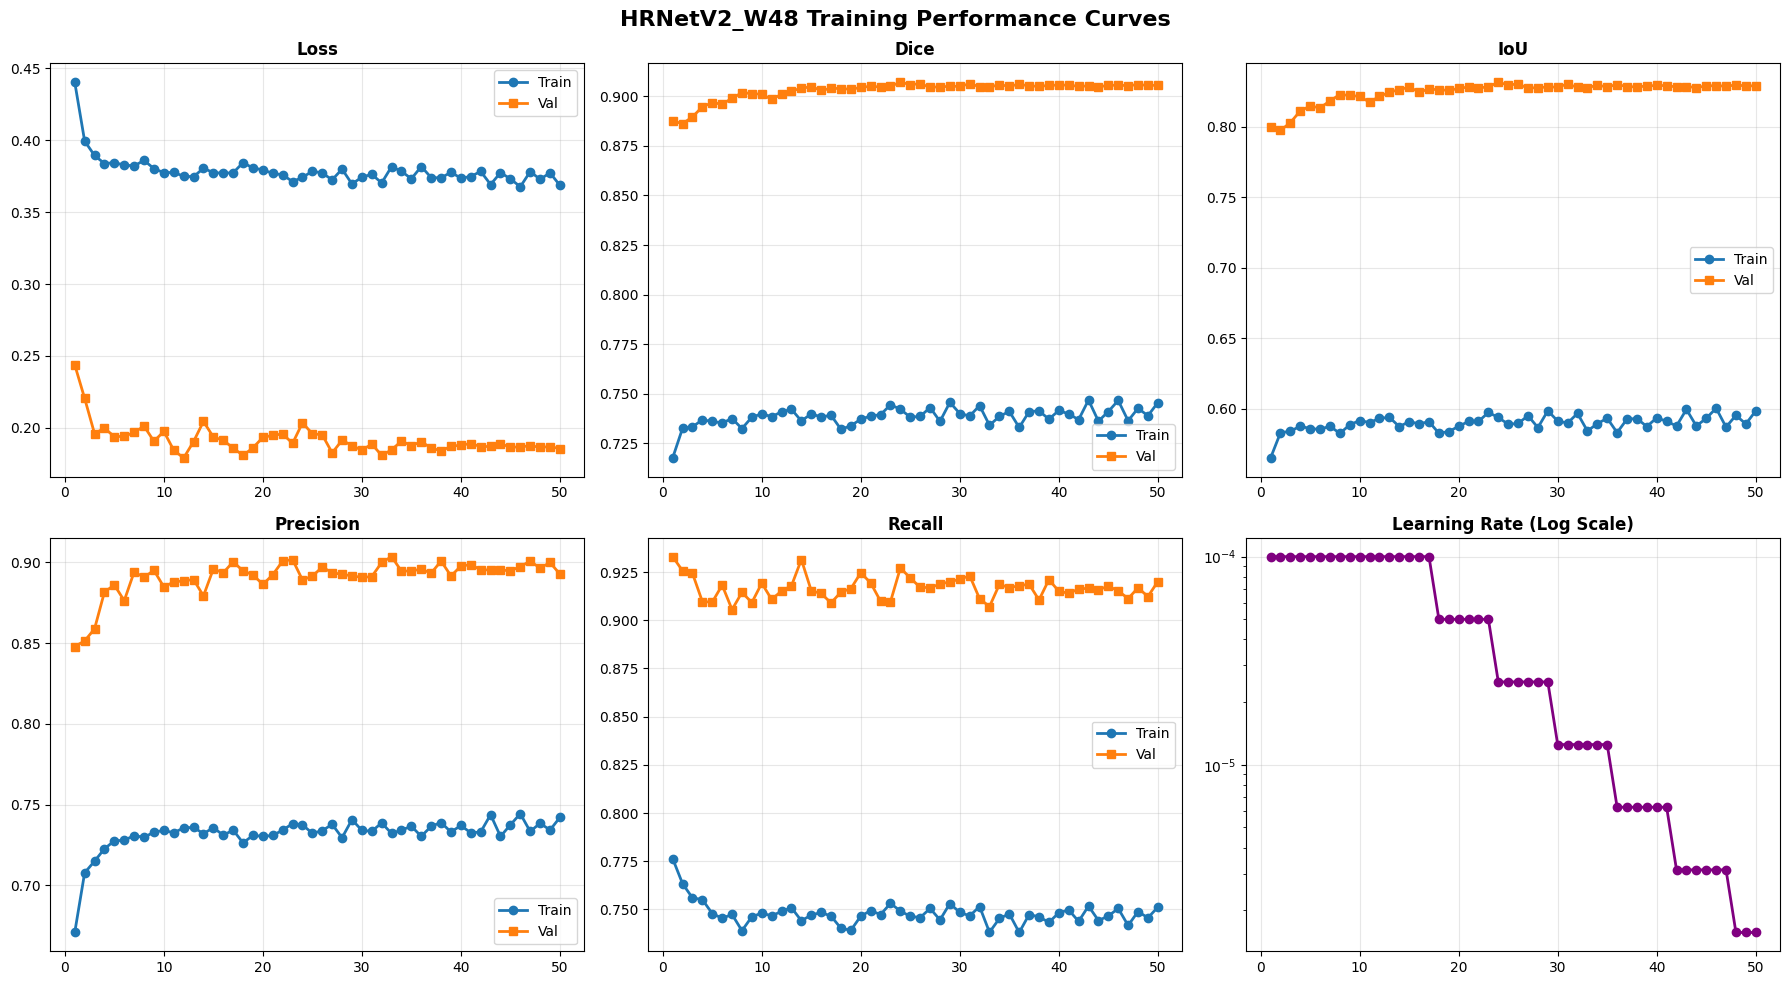

✅ Performance plot saved: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/HRNetV2_W48/training_curves.png


In [ ]:
epochs_range = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Define metrics for the subplots
metrics_to_plot = [
    ("loss", "Loss"),
    ("dice", "Dice"),
    ("iou", "IoU"),
    ("precision", "Precision"),
    ("recall", "Recall")
]

for i, (m, title) in enumerate(metrics_to_plot):
    row, col = divmod(i, 3)
    axes[row, col].plot(epochs_range, history[f"train_{m}"], "o-", label="Train", linewidth=2)
    axes[row, col].plot(epochs_range, history[f"val_{m}"], "s-", label="Val", linewidth=2)
    axes[row, col].set_title(title, fontweight="bold")
    axes[row, col].legend()
    axes[row, col].grid(alpha=0.3)

# Plot Learning Rate in the final subplot
axes[1, 2].plot(epochs_range, history["learning_rate"], "o-", color="purple", linewidth=2)
axes[1, 2].set_title("Learning Rate (Log Scale)", fontweight="bold")
axes[1, 2].set_yscale("log")
axes[1, 2].grid(alpha=0.3)

plt.suptitle(f"{MODEL_NAME} Training Performance Curves", fontsize=16, fontweight="bold")
plt.tight_layout()

# Save the training curve plot
plot_path = os.path.join(model_results_path, "training_curves.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Performance plot saved: {plot_path}")

In [ ]:
print("\n🎨 TEST PREDICTIONS VISUALIZATION (BINARY MASK STYLE)")
print("="*60)

best_model_path = os.path.join(model_results_path, "best_model.pth")
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

raw_ds = wds.WebDataset(wds_path).decode("pil").to_tuple("image.png", "mask.png")
all_samples = list(raw_ds)
random.seed(42)
num_samples = 8
test_indices = random.sample(range(CONFIG["train_size"] + CONFIG["val_size"], len(all_samples)), num_samples)

fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))
with torch.no_grad():
    for i, idx in enumerate(test_indices):
        img_pil, mask_pil = all_samples[idx]
        img_np = np.array(img_pil.convert("RGB"))
        mask_np = (np.array(mask_pil.convert("L")) / 255.0).astype(np.float32)

        t = val_transform(image=img_np, mask=mask_np)
        img_t = t["image"].unsqueeze(0).to(device)

        pred_prob = torch.sigmoid(model(img_t)).squeeze().cpu().numpy()
        pred_binary = (pred_prob > 0.5).astype(np.uint8)

        axes[i, 0].imshow(img_np.astype(np.uint8))
        axes[i, 0].set_title(f"Original Image\nSample {idx}", fontweight="bold", fontsize=14)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask_np, cmap='gray')
        axes[i, 1].set_title("Ground Truth", fontweight="bold", fontsize=14)
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_binary, cmap='gray')
        axes[i, 2].set_title("Prediction", fontweight="bold", fontsize=14)
        axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "prediction_samples_binary.png"), dpi=300, bbox_inches="tight")
plt.show()